# 32. Robustness checks

Here I collect a set of robustness checks. I use Binance spot BTCUSDT one-minute data from the development period only (2023-01 to 2026-04) and the stored results of notebooks 16, 22 and 29. These checks are exploratory, and they leave the preregistered confirmatory plan (H1, S, P1, P2) unchanged.

1. Events with no possible pre-onset alert, for window definitions H = 120, 240, 480 and 1440: event e has L_e = min(211, max(0, 240 − (breach − onset) minutes)) pre-onset minutes inside the judging window (30–240 minutes before the breach), and with L_e = 0 no model can issue a pre-onset alert by rule.
2. The π line: I hold the conditional performance (Δpre, Δin) at the 24-hour values, so the standard AUC difference is (1 − π)Δpre + πΔin. With the line, the crossover interval and the observed π I show that a change in π alone can flip the ranking (not that equal π implies equal ranking).
3. Common events: events of the 4-hour and 24-hour definitions whose breaches lie within 60 minutes of each other. I recompute GBM − M0 on their positive minutes only, keeping all negatives.
4. Type I error of the budget-preserving and circular-shift nulls on two families of surrogate series without predictive skill.
5. Bootstrap sensitivity to block length (3, 7, 14, 30 days), number of draws and leaving one month out.
6. Event-definition code against an independent implementation and boundary cases.

For the M0–M1 paired event tests I display the results already in `2a_paired_events_by_window.csv` of notebook 29. I fix the reading rules of each section in `32_SPEC.json`. I write the outputs to `robustness_checks_v1`.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
# Shared by notebooks 18 and 19: exact block-bootstrap AUC decomposition.
def week_pairs(sp, wp, sn, wn):
    """C[k, l] = over positives in block k, the number of negatives in block l with a lower score (+0.5 per tie).
    With block multiplicities w from the bootstrap, the AUC is w'Cw / ((w'P)(w'N)); w = 1 gives the ordinary AUC."""
    C = np.zeros((N_WEEKS, N_WEEKS))
    if len(sp) == 0 or len(sn) == 0:
        return C
    o = np.lexsort((sn, wn)); sn = sn[o]; wn = wn[o]
    bounds = np.searchsorted(wn, np.arange(N_WEEKS + 1), 'left')
    for l in range(N_WEEKS):
        a, b = bounds[l], bounds[l + 1]
        if a == b:
            continue
        seg = sn[a:b]; lo = np.searchsorted(seg, sp, 'left'); hi = np.searchsorted(seg, sp, 'right')
        C[:, l] = np.bincount(wp, weights=lo + 0.5 * (hi - lo), minlength=N_WEEKS)
    return C


def _ratio(a, b):
    return a / b if b > 0 else np.nan


STAT_KEYS = ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'diff_standard_minus_pre', 'in_share_of_excess', 'auc_calm',
             'auc_standard_within_regime', 'auc_pre_within_regime', 'auc_in_within_regime']


def make_parts(sm, code, calm, wk, dec):
    neg = code == 0; pre = code == 1; inn = code == 2; cnt = lambda k: np.bincount(wk[k], minlength=N_WEEKS).astype(float)
    P = dict(C_pre=week_pairs(sm[pre], wk[pre], sm[neg], wk[neg]), C_in=week_pairs(sm[inn], wk[inn], sm[neg], wk[neg]),
             C_calm=week_pairs(sm[(code > 0) & calm], wk[(code > 0) & calm], sm[neg & calm], wk[neg & calm]),
             P_pre=cnt(pre), P_in=cnt(inn), N=cnt(neg), P_calm=cnt((code > 0) & calm), N_calm=cnt(neg & calm),
             Cs_pre=np.zeros((N_WEEKS, N_WEEKS)), Cs_in=np.zeros((N_WEEKS, N_WEEKS)), Pq_pre=[], Pq_in=[], Nq=[])
    for q in range(10):
        kq = dec == q; nq = neg & kq; pq = pre & kq; iq = inn & kq
        P['Cs_pre'] += week_pairs(sm[pq], wk[pq], sm[nq], wk[nq]); P['Cs_in'] += week_pairs(sm[iq], wk[iq], sm[nq], wk[nq])
        P['Pq_pre'].append(cnt(pq)); P['Pq_in'].append(cnt(iq)); P['Nq'].append(cnt(nq))
    for k in ('Pq_pre', 'Pq_in', 'Nq'):
        P[k] = np.array(P[k])
    return P


def stats_from(P, w):
    q = lambda C: w @ C @ w
    Wn = w @ P['N']; Wp = w @ P['P_pre']; Wi = w @ P['P_in']; sp = q(P['C_pre']); si = q(P['C_in'])
    std = _ratio(sp + si, (Wp + Wi) * Wn); pre = _ratio(sp, Wp * Wn); inn = _ratio(si, Wi * Wn); pi = _ratio(Wi, Wp + Wi)
    nq = P['Nq'] @ w; pq = P['Pq_pre'] @ w; iq = P['Pq_in'] @ w; ssp = q(P['Cs_pre']); ssi = q(P['Cs_in'])
    return dict(auc_standard=std, auc_pre=pre, auc_in=inn, share_in=pi, diff_standard_minus_pre=std - pre,
                in_share_of_excess=_ratio(pi * (inn - 0.5), std - 0.5) if np.isfinite(inn) else 0.0,
                auc_calm=_ratio(q(P['C_calm']), (w @ P['P_calm']) * (w @ P['N_calm'])),
                auc_standard_within_regime=_ratio(ssp + ssi, ((pq + iq) * nq).sum()),
                auc_pre_within_regime=_ratio(ssp, (pq * nq).sum()), auc_in_within_regime=_ratio(ssi, (iq * nq).sum()))
import joblib
from scipy.stats import kstest

OUT = SPOT_BASE / 'robustness_checks_v1'; OUT.mkdir(parents=True, exist_ok=True)
M16 = SPOT_BASE / 'methods_definitions_v1'
M22 = SPOT_BASE / 'peak_window_v1'
M29 = SPOT_BASE / 'ranking_vix_baseline_v1'
DNAME, DCL = '4pct', 0.04
H_LIST = [120, 240, 480, 1440]; H_REF = 240; H_24 = 1440
PSCORES = ['M0_VF_logit', 'M1_vol_threshold', 'M3_GBM_rich', 'B0_RV24h_baseline']
ALERT_METHODS = ['M0_VF_logit', 'M1_vol_threshold', 'M2_VPIN', 'M3_GBM_rich']
SEED = 20261031
N_BOOT = 500; BLOCK_DAYS = 7                      # as in notebooks 22 and 29
BLOCKS_SENS = [3, 7, 14, 30]; N_BOOT_SENS = 2000   # section 5
R_CAL = 400; R_CAL2 = 200; N_CAL = 400; SHIFT_MIN_D = 30; N_SHUFFLE_BLOCKS = 40; BP_TRIES = 64   # section 4: shift family, block-shuffle family, draws per test
COMMON_TOL_MIN = 60                                # section 3
EVAL_LAST = ts(EVAL_END).value - (LEAD_MAX + 5) * NS
WINDOW_MIN = LEAD_MAX - LEAD_MIN + 1               # 211 judged minutes per event

for _p in [M16 / 'METHODS_FROZEN.json', M16 / 'METHODS_SPEC.json', M16 / '4_methods_definitions_nulls.csv', M22 / '2_per_minute_by_window.csv',
           M29 / '1a_scores_by_window_common_minutes.csv', M29 / '1c_crossover_by_window.csv', M29 / '2a_paired_events_by_window.csv']:
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 16, 22 and 29 are required: {_p}')
FROZEN16 = json.loads((M16 / 'METHODS_FROZEN.json').read_text()); SPEC16 = json.loads((M16 / 'METHODS_SPEC.json').read_text())
if sha256_file(M16 / 'METHODS_SPEC.json') != FROZEN16['spec_sha256'] or SPEC16['gbm_params'] != GBM_PARAMS or SPEC16['gbm_features'] != FEATS:
    raise RuntimeError('GUARD FAIL: notebook-16 spec/settings differ')

SPEC = {'title': 'Reviewer-requested robustness checks on the development sample (exploratory; appendix)',
        'inputs': 'spot cache, notebook-16 frozen models/alerts, notebook-22 window catalogs, notebook-29 results; holdouts and the prospective folder not read',
        'section1': {'possible_minutes': f'L_e = min({WINDOW_MIN}, max(0, {LEAD_MAX} - (breach - onset) minutes)); L_e = 0 means no pre-onset warning is possible under the 30-240 rule',
                     'check': 'pi implied by L equals the notebook-22 share_in on the same minutes'},
        'section2': {'line': 'standard-AUC difference (GBM - M0) = (1 - pi) * dpre + pi * din with dpre, din fixed at the 24-hour definition; crossover interval from notebook 29',
                     'claim': 'with conditional performance fixed, a change in pi alone can reverse the ranking (not: equal pi implies equal ranking)'},
        'section3': {'common': f'an H=240 event and an H=1440 event are the same event if their breaches are within {COMMON_TOL_MIN} minutes',
                     'analysis': 'positives restricted to common events under each definition, negatives unchanged; GBM - M0 differences with the shared block bootstrap'},
        'section4': {'surrogate_shift': f'M0 score circularly shifted within the evaluation period by at least {SHIFT_MIN_D} days (both directions), frozen threshold and calendar scheduler re-run',
                     'surrogate_block_shuffle': f'M0 score cut into {N_SHUFFLE_BLOCKS} equal-length blocks over the evaluation period and the blocks permuted with no block left in place (derangement); within-block autocorrelation kept, alignment with events destroyed',
                     'tests': 'budget-preserving regime-matched null (notebook 26/31 code), circular >=7d and circular 4h-1d nulls (notebook 16 code)',
                     'replications': {'shift': R_CAL, 'block_shuffle': R_CAL2}, 'draws_per_test': N_CAL, 'reading': 'no evidence of size distortion if the 95% interval of the rejection rate at alpha = 0.05 covers 0.05; conservative if below; anti-conservative if above; surrogates from one series are not independent samples'},
        'section5': {'blocks_days': BLOCKS_SENS, 'draws': N_BOOT_SENS, 'targets': 'H=1440 GBM - M0 standard and pre-onset AUC; H=240 M0 in-progress share of excess AUC',
                     'leave_one_month_out': 'point estimates with each calendar month removed (month blocks, weight 0)'},
        'section6': 'independent plain-loop implementation of the price-only event rule compared with the frozen function on synthetic series and boundary cases',
        'seed': SEED, 'notebook16_spec_sha256': FROZEN16['spec_sha256'], 'holdouts': 'not used', 'status': 'exploratory; appendix; no confirmatory plan changed'}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
_sp = OUT / '32_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    _sp.rename(OUT / f'32_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
_sp.write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16])

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/robustness_checks_v1 | spec sha256 d52a5e736a42dc05


## 0. Reproduction of scores, alerts and events by window (same code as A1 of notebook 29)

In [2]:
t_ = time.time()
px, sg = load_btc_spot()
F = causal_features(px, sg)
T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float)
v_ = sg.z_vol.to_numpy(float); f_ = sg.tsr.to_numpy(float); h_ = sg.z_hs.to_numpy(float)
VALID = (np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v_) & np.isfinite(f_) & np.isfinite(h_) & (f_ >= 0) & (f_ <= 1))
EVM = VALID & (T >= ts(EVAL_START).value) & (T < EVAL_LAST)
EVP = VALID & in_period(T, EVAL_START, EVAL_END)          # notebook-16 alert eligibility
DD240 = F.dd_240.to_numpy(float); CALM = np.isfinite(DD240) & (DD240 < DCL / 4)
_lc = np.log(np.where(np.isfinite(close) & (close > 0), close, np.nan))
RV = pd.Series(_lc).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()
DEC = np.full(len(T), -1, np.int64); _okr = EVM & np.isfinite(RV)
DEC[_okr] = np.minimum((pd.Series(RV[_okr]).rank(pct=True).to_numpy() * 10).astype(int), 9)
WEEK = np.where(EVM, (T - ts(EVAL_START).value) // (BLOCK_DAYS * 1440 * NS), -1).astype(np.int64)
N_WEEKS = int(WEEK[EVM].max()) + 1
TCOLS = ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']


def catalog_H(H):
    E_ = price_only_catalog(close, volume, px.index, H=H, decline=DCL)
    for c_ in TCOLS:
        E_[c_] = pd.to_datetime(E_[c_], utc=True)
    return E_.sort_values('breach_utc').reset_index(drop=True)


def in_decline_mask(E_, y_):
    br = E_.breach_utc.astype('int64').to_numpy(); on = E_.onset_1pct_utc.astype('int64').to_numpy()
    pos = np.searchsorted(br, T + LEAD_MIN * NS, 'left'); ok = pos < len(br)
    inn = np.zeros(len(T), bool); inn[ok] = T[ok] >= on[pos[ok]]
    return inn & (y_ == 1)


def event_of_minute(E_, y_):
    """Index (row) of the event that makes each positive minute positive; -1 elsewhere."""
    br = E_.breach_utc.astype('int64').to_numpy(); pos = np.searchsorted(br, T + LEAD_MIN * NS, 'left')
    out = np.full(len(T), -1, np.int64); ok = (y_ == 1) & (pos < len(br)); out[ok] = pos[ok]
    return out


E_ref = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
CAT = {H: catalog_H(H) for H in H_LIST}
if len(CAT[H_REF]) != len(E_ref) or any(not np.array_equal(CAT[H_REF][c_].astype('int64').to_numpy(), E_ref[c_].astype('int64').to_numpy()) for c_ in TCOLS):
    raise RuntimeError('GUARD FAIL: H=240 catalog differs from the notebook-2 catalog')
EV = {H: events_between(CAT[H], EVAL_START, EVAL_END).reset_index(drop=True) for H in H_LIST}
Xl = F[['z_vol', 'tsr']].to_numpy(float); okl = train_mask(T, VALID) & np.isfinite(Xl).all(axis=1)
cfg0 = FROZEN16['configs'][f'M0_VF_logit|{DNAME}']
m0 = new_logit().fit(Xl[okl], label_from_catalog(T, CAT[H_REF])[okl])
if not (np.allclose(m0[-1].coef_.ravel(), cfg0['coef'], rtol=1e-6, atol=1e-9) and np.isclose(m0[-1].intercept_[0], cfg0['intercept'], rtol=1e-6, atol=1e-9)):
    raise RuntimeError('GUARD FAIL: M0 refit differs from notebook 16')
cfg3 = FROZEN16['configs'][f'M3_GBM_rich|{DNAME}']; mp = SPOT_BASE / cfg3['model_file']
if sha256_file(mp) != cfg3['model_sha256']:
    raise RuntimeError('GUARD FAIL: notebook-16 GBM file SHA-256 differs')
g3 = joblib.load(mp)
IDX = np.flatnonzero(EVM); S = {}
s = np.full(len(T), np.nan); okp = EVM & np.isfinite(Xl).all(axis=1); s[okp] = m0.predict_proba(Xl[okp])[:, 1]; S['M0_VF_logit'] = s
S['M1_vol_threshold'] = np.where(VALID, F.z_vol.to_numpy(float), np.nan)
s = np.full(len(T), np.nan); s[IDX] = g3.predict_proba(F[FEATS].to_numpy(np.float32)[IDX])[:, 1]; S['M3_GBM_rich'] = s
S['B0_RV24h_baseline'] = np.where(VALID, RV, np.nan)
TH0 = float(cfg0['threshold_2022'])
# M0 score on every valid minute of the evaluation period (section 4 re-runs the scheduler on it)
S0_FULL = np.full(len(T), np.nan); okf = EVP & np.isfinite(Xl).all(axis=1); S0_FULL[okf] = m0.predict_proba(Xl[okf])[:, 1]
ALERTS = {}
for mname in ALERT_METHODS:
    a = np.sort(pd.to_datetime(pd.read_csv(M16 / f'alarms_{mname}_{DNAME}.csv').alarm_utc, utc=True).astype('int64').to_numpy())
    if len(a) != FROZEN16['configs'][f'{mname}|{DNAME}']['dev_alerts']:
        raise RuntimeError(f'GUARD FAIL: notebook-16 alarms for {mname} changed')
    ALERTS[mname] = a
_ok0 = EVP & np.isfinite(S0_FULL); _a0 = emit_calendar_fast(T[_ok0], S0_FULL[_ok0] >= TH0)
if not np.array_equal(_a0, ALERTS['M0_VF_logit']):
    raise RuntimeError('GUARD FAIL: re-running the frozen scheduler on the M0 score does not reproduce the notebook-16 alerts')
del Xl

PM22 = pd.read_csv(M22 / '2_per_minute_by_window.csv'); ONES = np.ones(N_WEEKS); LAB = {}; EVOF = {}
for H in H_LIST:
    yH = label_from_catalog(T, CAT[H]); innH = in_decline_mask(CAT[H], yH)
    LAB[H] = np.where(yH == 1, np.where(innH, 2, 1), 0).astype(np.int64); EVOF[H] = event_of_minute(CAT[H], yH)
    for sname in PSCORES:
        m = EVM & np.isfinite(S[sname]) & (DEC >= 0)
        pt = stats_from(make_parts(S[sname][m], LAB[H][m], CALM[m], WEEK[m], DEC[m]), ONES)
        ref = PM22[(PM22.H == H) & (PM22.score == sname)]
        if len(ref) != 1 or any(abs(pt[k] - float(ref.iloc[0][k])) > 1e-9 for k in ['auc_standard', 'auc_pre', 'auc_in', 'auc_pre_within_regime']):
            raise RuntimeError(f'GUARD FAIL: per-minute point estimate differs from notebook 22 (H={H}, {sname})')
MC = EVM & (DEC >= 0)
for sname in PSCORES:
    MC &= np.isfinite(S[sname])
print(f'PASS: notebook-16 scores, alerts and scheduler verified; per-minute point estimates equal notebook 22 at every window ({time.time() - t_:.0f}s)')
print('events in the development period by window:', {H: len(EV[H]) for H in H_LIST})

PASS: notebook-16 scores, alerts and scheduler verified; per-minute point estimates equal notebook 22 at every window (144s)
events in the development period by window: {120: 51, 240: 83, 480: 129, 1440: 218}


## 1. Events for which a pre-onset alert is impossible by rule (by window definition)

In [3]:
rows = []; erows = []
for H in H_LIST:
    ev = EV[H]; gap = ev.onset_to_breach_minutes.to_numpy(float)
    L = np.clip(LEAD_MAX - gap, 0, WINDOW_MIN)
    cond = {}
    for mname in ALERT_METHODS:
        mm = match_events(ev, ALERTS[mname]); pre_ids = set(mm.loc[mm.pre1pct, 'event_id'].astype(int))
        pre_possible = set(ev.loc[L > 0, 'event_id'].astype(int))
        cond[mname] = dict(pre=len(pre_ids), pre_rate_all=len(pre_ids) / max(1, len(ev)), pre_rate_possible=len(pre_ids & pre_possible) / max(1, len(pre_possible)),
                           pre_in_impossible=len(pre_ids - pre_possible))
    lab = LAB[H][MC]; share_in_minutes = float((lab == 2).sum() / max(1, (lab > 0).sum()))
    rows.append(dict(H=H, events=len(ev), impossible_events=int((L == 0).sum()), impossible_share=float((L == 0).mean()),
                     full_window_events=int((gap < LEAD_MIN).sum()), median_possible_minutes=float(np.median(L)), mean_possible_minutes=float(L.mean()),
                     median_onset_to_breach_min=float(np.median(gap)),
                     pi_implied_by_L=1 - float(L.sum() / (WINDOW_MIN * max(1, len(ev)))), pi_share_in_minutes=share_in_minutes,
                     **{f'{m}_pre_catches': cond[m]['pre'] for m in ALERT_METHODS},
                     **{f'{m}_pre_rate_all_events': cond[m]['pre_rate_all'] for m in ALERT_METHODS},
                     **{f'{m}_pre_rate_possible_events': cond[m]['pre_rate_possible'] for m in ALERT_METHODS},
                     **{f'{m}_pre_catches_in_impossible_events': cond[m]['pre_in_impossible'] for m in ALERT_METHODS}))
    for e_, g_, l_ in zip(ev.event_id, gap, L):
        erows.append(dict(H=H, event_id=int(e_), onset_to_breach_min=int(g_), pre_onset_possible_minutes=int(l_)))
POS = pd.DataFrame(rows); POS.to_csv(OUT / '1_pre_onset_possible_by_window.csv', index=False)
pd.DataFrame(erows).to_csv(OUT / '1b_events_pre_onset_minutes.csv', index=False)
if (POS[[f'{m}_pre_catches_in_impossible_events' for m in ALERT_METHODS]].to_numpy() != 0).any():
    raise RuntimeError('GUARD FAIL: a pre-onset catch was matched to an event with no pre-onset minute in the window')
display(POS[['H', 'events', 'impossible_events', 'impossible_share', 'full_window_events', 'median_possible_minutes', 'median_onset_to_breach_min', 'pi_implied_by_L', 'pi_share_in_minutes',
             'M0_VF_logit_pre_catches', 'M0_VF_logit_pre_rate_all_events', 'M0_VF_logit_pre_rate_possible_events', 'M3_GBM_rich_pre_catches', 'M3_GBM_rich_pre_rate_possible_events']].round(3))
print('pi implied by the onset-to-breach gaps vs the share of in-progress positive minutes (they differ only through invalid minutes and overlapping windows):')
print(POS[['H', 'pi_implied_by_L', 'pi_share_in_minutes']].round(4).to_string(index=False))

,H,events,impossible_events,impossible_share,full_window_events,median_possible_minutes,median_onset_to_breach_min,pi_implied_by_L,pi_share_in_minutes,M0_VF_logit_pre_catches,M0_VF_logit_pre_rate_all_events,M0_VF_logit_pre_rate_possible_events,M3_GBM_rich_pre_catches,M3_GBM_rich_pre_rate_possible_events
0,120,51,0,0.000,13,186.0,54.0,0.140,0.140,13,0.255,0.255,8,0.157
1,240,83,0,0.000,8,121.0,119.0,0.414,0.414,22,0.265,0.265,7,0.084
2,480,129,65,0.504,7,0.0,240.0,0.706,0.706,16,0.124,0.250,4,0.062
3,1440,218,188,0.862,4,0.0,819.5,0.914,0.914,5,0.023,0.167,1,0.033


pi implied by the onset-to-breach gaps vs the share of in-progress positive minutes (they differ only through invalid minutes and overlapping windows):
   H  pi_implied_by_L  pi_share_in_minutes
 120           0.1402               0.1402
 240           0.4137               0.4137
 480           0.7059               0.7059
1440           0.9137               0.9137


## 2. The π line: the π at which the ranking flips under fixed conditional performance

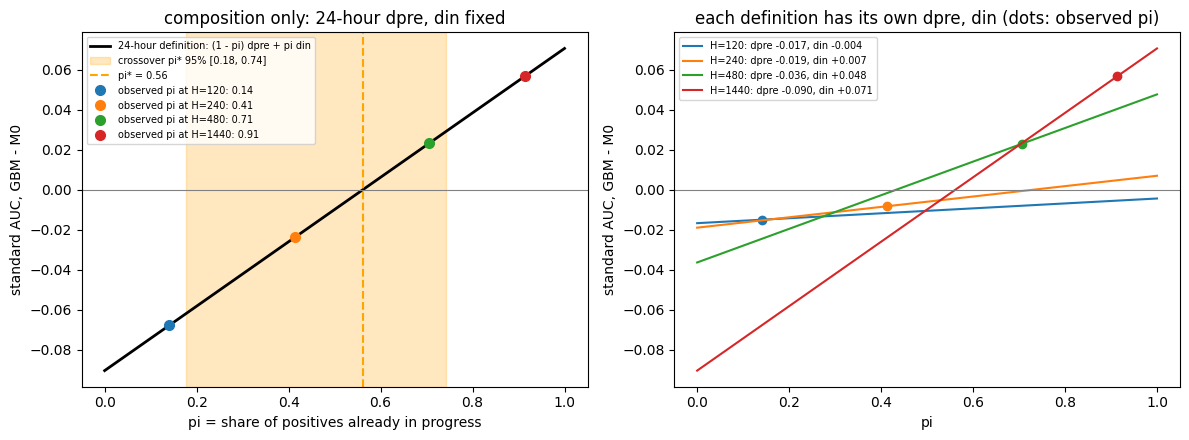

24-hour definition: observed pi 0.914; crossover pi* 0.561 [0.177, 0.742] (defined in 99% of draws)


In [4]:
SC29 = pd.read_csv(M29 / '1a_scores_by_window_common_minutes.csv'); XO29 = pd.read_csv(M29 / '1c_crossover_by_window.csv')
pi_grid = np.linspace(0, 1, 201); lrows = []; fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for H in H_LIST:
    ga = SC29[(SC29.H == H) & (SC29.score == 'M3_GBM_rich')].iloc[0]; m0r = SC29[(SC29.H == H) & (SC29.score == 'M0_VF_logit')].iloc[0]
    dpre, din = float(ga.auc_pre - m0r.auc_pre), float(ga.auc_in - m0r.auc_in)
    line = (1 - pi_grid) * dpre + pi_grid * din
    xo = XO29[(XO29.H == H) & (XO29.pair == 'M3_GBM_rich - M0_VF_logit')].iloc[0]
    for p_, v_ in zip(pi_grid, line):
        lrows.append(dict(H=H, pi=p_, standard_auc_diff_gbm_minus_m0=v_, dpre=dpre, din=din, pi_observed=float(xo.pi_observed), crossover_pi=xo.crossover_pi,
                          crossover_lo=xo.crossover_lo, crossover_hi=xo.crossover_hi, share_draws_defined=xo.share_draws_defined))
    ax[1].plot(pi_grid, line, label=f'H={H}: dpre {dpre:+.3f}, din {din:+.3f}'); ax[1].plot([xo.pi_observed], [(1 - xo.pi_observed) * dpre + xo.pi_observed * din], 'o', color=ax[1].lines[-1].get_color())
    if H == H_24:
        ax[0].plot(pi_grid, line, color='k', lw=2, label='24-hour definition: (1 - pi) dpre + pi din')
        if np.isfinite(xo.crossover_lo) and np.isfinite(xo.crossover_hi):
            ax[0].axvspan(xo.crossover_lo, xo.crossover_hi, color='orange', alpha=0.25, label=f'crossover pi* 95% [{xo.crossover_lo:.2f}, {xo.crossover_hi:.2f}]')
        if np.isfinite(xo.crossover_pi):
            ax[0].axvline(xo.crossover_pi, color='orange', ls='--', label=f'pi* = {xo.crossover_pi:.2f}')
        for H2 in H_LIST:
            p2 = float(XO29[(XO29.H == H2) & (XO29.pair == 'M3_GBM_rich - M0_VF_logit')].pi_observed.iloc[0])
            ax[0].plot([p2], [(1 - p2) * dpre + p2 * din], 'o', ms=7, label=f'observed pi at H={H2}: {p2:.2f}')
ax[0].axhline(0, color='grey', lw=0.8); ax[0].set_xlabel('pi = share of positives already in progress'); ax[0].set_ylabel('standard AUC, GBM - M0'); ax[0].legend(fontsize=7); ax[0].set_title('composition only: 24-hour dpre, din fixed')
ax[1].axhline(0, color='grey', lw=0.8); ax[1].set_xlabel('pi'); ax[1].set_ylabel('standard AUC, GBM - M0'); ax[1].legend(fontsize=7); ax[1].set_title('each definition has its own dpre, din (dots: observed pi)')
plt.tight_layout(); plt.savefig(OUT / '2_pi_line.png', dpi=140); plt.show()
PL = pd.DataFrame(lrows); PL.to_csv(OUT / '2_pi_line.csv', index=False)
x24 = XO29[(XO29.H == H_24) & (XO29.pair == 'M3_GBM_rich - M0_VF_logit')].iloc[0]
print(f'24-hour definition: observed pi {x24.pi_observed:.3f}; crossover pi* {x24.crossover_pi:.3f} [{x24.crossover_lo:.3f}, {x24.crossover_hi:.3f}] (defined in {100 * x24.share_draws_defined:.0f}% of draws)')

## 3. Common events of the 4-hour and 24-hour definitions

In [5]:
t_ = time.time()
ev4, ev24 = EV[H_REF], EV[H_24]
b4 = ev4.breach_utc.astype('int64').to_numpy(); b24 = ev24.breach_utc.astype('int64').to_numpy()
pairs = []; used24 = set()
for i4, b_ in enumerate(b4):
    j = int(np.argmin(np.abs(b24 - b_)))
    if abs(b24[j] - b_) <= COMMON_TOL_MIN * NS and j not in used24:
        used24.add(j); pairs.append((i4, j))
PR = pd.DataFrame([dict(event_id_H240=int(ev4.event_id[i]), event_id_H1440=int(ev24.event_id[j]),
                        breach_diff_min=int((b24[j] - b4[i]) // NS),
                        onset_diff_min_24h_minus_4h=int((ev24.onset_1pct_utc[j].value - ev4.onset_1pct_utc[i].value) // NS),
                        peak_diff_min_24h_minus_4h=int((ev24.peak_utc[j].value - ev4.peak_utc[i].value) // NS),
                        gap_4h=int(ev4.onset_to_breach_minutes[i]), gap_24h=int(ev24.onset_to_breach_minutes[j])) for i, j in pairs])
PR.to_csv(OUT / '3b_common_event_pairs.csv', index=False)
print(f'common events: {len(PR)} of {len(ev4)} (4h) and {len(ev24)} (24h); identical breach minute in {int((PR.breach_diff_min == 0).sum())} of them')
print(f'onset moves earlier under the 24-hour definition by a median of {-PR.onset_diff_min_24h_minus_4h.median():.0f} minutes; '
      f'pre-onset window minutes: 4h median {np.median(np.clip(LEAD_MAX - PR.gap_4h, 0, WINDOW_MIN)):.0f}, 24h median {np.median(np.clip(LEAD_MAX - PR.gap_24h, 0, WINDOW_MIN)):.0f}')


def restricted_code(H, keep_rows):
    """Labels with positives kept only for the events in keep_rows (catalog row numbers); other positives excluded (-1); negatives unchanged."""
    code = LAB[H].copy(); drop = (code > 0) & ~np.isin(EVOF[H], keep_rows)
    code[drop] = -1
    return code


rows = []; rng = np.random.default_rng(SEED + 3)
W_BOOT = [np.bincount(rng.integers(0, N_WEEKS, N_WEEKS), minlength=N_WEEKS).astype(float) for _ in range(N_BOOT)]
keep = {H_REF: np.array([int(np.flatnonzero(CAT[H_REF].event_id.to_numpy() == e)[0]) for e in PR.event_id_H240]),
        H_24: np.array([int(np.flatnonzero(CAT[H_24].event_id.to_numpy() == e)[0]) for e in PR.event_id_H1440])}
for H in [H_REF, H_24]:
    for subset in ['all events', 'common events only']:
        code = LAB[H] if subset == 'all events' else restricted_code(H, keep[H])
        m = MC & (code >= 0)
        PP = {sn: make_parts(S[sn][m], code[m], CALM[m], WEEK[m], DEC[m]) for sn in ['M0_VF_logit', 'M3_GBM_rich']}
        pt = {sn: stats_from(PP[sn], ONES) for sn in PP}
        bt = {k: np.array([stats_from(PP['M3_GBM_rich'], w)[k] - stats_from(PP['M0_VF_logit'], w)[k] for w in W_BOOT]) for k in ['auc_standard', 'auc_pre', 'auc_pre_within_regime']}
        row = dict(H=H, subset=subset, positives=int((code[m] > 0).sum()), share_in=pt['M0_VF_logit']['share_in'],
                   m0_standard=pt['M0_VF_logit']['auc_standard'], gbm_standard=pt['M3_GBM_rich']['auc_standard'], m0_pre=pt['M0_VF_logit']['auc_pre'], gbm_pre=pt['M3_GBM_rich']['auc_pre'])
        for k in bt:
            lo, hi = np.nanpercentile(bt[k], [2.5, 97.5]); row[f'diff_{k}'] = pt['M3_GBM_rich'][k] - pt['M0_VF_logit'][k]; row[f'diff_{k}_lo'] = lo; row[f'diff_{k}_hi'] = hi
        row['reading'] = ('reversal: GBM ahead on standard, M0 ahead on pre-onset' if row['diff_auc_standard_lo'] > 0 and row['diff_auc_pre_hi'] < 0 else
                          'no reversal' if row['diff_auc_standard_hi'] < 0 or row['diff_auc_pre_lo'] > 0 else 'not distinguishable')
        rows.append(row); print(f'H={H:4d} {subset:19s} positives {row["positives"]:7d} pi {row["share_in"]:.3f} | GBM-M0 standard {row["diff_auc_standard"]:+.4f} [{row["diff_auc_standard_lo"]:+.4f}, {row["diff_auc_standard_hi"]:+.4f}] | pre-onset {row["diff_auc_pre"]:+.4f} [{row["diff_auc_pre_lo"]:+.4f}, {row["diff_auc_pre_hi"]:+.4f}] ({time.time() - t_:.0f}s)', flush=True)
CE = pd.DataFrame(rows); CE.to_csv(OUT / '3_common_events.csv', index=False); display(CE.round(4))

common events: 52 of 83 (4h) and 218 (24h); identical breach minute in 29 of them
onset moves earlier under the 24-hour definition by a median of 119 minutes; pre-onset window minutes: 4h median 136, 24h median 50
H= 240 all events          positives   17513 pi 0.414 | GBM-M0 standard -0.0081 [-0.0374, +0.0206] | pre-onset -0.0189 [-0.0579, +0.0214] (8s)
H= 240 common events only  positives   10972 pi 0.358 | GBM-M0 standard -0.0270 [-0.0634, +0.0111] | pre-onset -0.0424 [-0.0967, +0.0137] (15s)
H=1440 all events          positives   45998 pi 0.914 | GBM-M0 standard +0.0568 [+0.0327, +0.0812] | pre-onset -0.0903 [-0.1757, -0.0140] (26s)
H=1440 common events only  positives   10972 pi 0.648 | GBM-M0 standard -0.0283 [-0.0656, +0.0112] | pre-onset -0.0844 [-0.1747, -0.0049] (33s)


,H,subset,positives,share_in,m0_standard,gbm_standard,m0_pre,gbm_pre,diff_auc_standard,diff_auc_standard_lo,diff_auc_standard_hi,diff_auc_pre,diff_auc_pre_lo,diff_auc_pre_hi,diff_auc_pre_within_regime,diff_auc_pre_within_regime_lo,diff_auc_pre_within_regime_hi,reading
0,240,all events,17513,0.4137,0.7633,0.7551,0.6728,0.6540,-0.0081,-0.0374,0.0206,-0.0189,-0.0579,0.0214,-0.0456,-0.0887,0.0005,not distinguishable
1,240,common events only,10972,0.3576,0.7371,0.7101,0.6555,0.6132,-0.0270,-0.0634,0.0111,-0.0424,-0.0967,0.0137,-0.0714,-0.1334,-0.0093,not distinguishable
2,1440,all events,45998,0.9137,0.6958,0.7526,0.7068,0.6165,0.0568,0.0327,0.0812,-0.0903,-0.1757,-0.0140,-0.1394,-0.2262,-0.0573,"reversal: GBM ahead on standard, M0 ahead on p..."
3,1440,common events only,10972,0.6484,0.7278,0.6996,0.7077,0.6233,-0.0283,-0.0656,0.0112,-0.0844,-0.1747,-0.0049,-0.1334,-0.2225,-0.0492,not distinguishable


## 4. Calibration of the null models: type I error on two surrogate families

I build two surrogate families from the M0 score: 400 series shifted circularly by at least 30 days, and 200 series cut into 40 equal-length blocks of about 30 days and shuffled with no block left in place. For each surrogate I build alerts with the frozen threshold and the calendar scheduler, count the pre-onset catches of the real 4% events, and compute p-values under three nulls (budget-preserving regime-matched, circular shift of at least 7 days, circular shift of 4 hours to 1 day). These alerts carry no information on event timing, so the 5% tests should reject about 5% of the time. The surrogates come from the same development series and are not fully independent, so I read the result as evidence for or against serious size distortion.

In [6]:
def ev_arrays(ev):
    return dict(br=ev.breach_utc.astype('int64').to_numpy(), on=ev.onset_1pct_utc.astype('int64').to_numpy(), pk=ev.peak_utc.astype('int64').to_numpy(), n=len(ev))


def fast_counts(a, ea):
    a = np.sort(np.asarray(a, np.int64)); used = np.zeros(len(a), bool); pre = post = 0
    for k in range(ea['n']):
        b = ea['br'][k]; l_ = np.searchsorted(a, b - LEAD_MAX * NS, 'left'); r_ = np.searchsorted(a, b - LEAD_MIN * NS, 'right')
        for j in range(l_, r_):
            if not used[j]:
                used[j] = True
                if a[j] < ea['on'][k]:
                    pre += 1
                else:
                    post += 1
                break
    return dict(pre=pre, post=post)


DQ_ORDER = [sorted(range(10), key=lambda d, q=q: (abs(d - q), d)) for q in range(10)]


def make_space(Tp, RVp, start, end):
    okd = (Tp >= start.value) & (Tp < end.value) & np.isfinite(RVp)
    tt = Tp[okd]; dq = np.minimum((pd.Series(RVp[okd]).rank(pct=True).to_numpy() * 10).astype(int), 9)
    mo = cal_fields(tt)[1]; key = mo * 10 + dq; o2 = np.lexsort((tt, key))
    return dict(TT=tt, DD=dq, PK=tt[o2], KS=key[o2])


def draw_budget(a, rng, sp, audit=None):
    """Budget-preserving regime-matched draw (notebook 26/31 code): same calendar month, same (or nearest) RV decile, >= 240 min from the original
    and from every alert already placed; if the decile search fails, every minute of the month is scanned; only if no feasible minute exists does the alert keep its time."""
    import bisect
    a = np.asarray(a, np.int64); j = np.clip(np.searchsorted(sp['TT'], a, 'right') - 1, 0, len(sp['TT']) - 1)
    q0 = sp['DD'][j]; mo = cal_fields(a)[1]; KS, PK = sp['KS'], sp['PK']
    placed = []; out = np.empty(len(a), np.int64); exact = near = anyq = failed = viol = 0
    for i in rng.permutation(len(a)):
        ai = int(a[i]); done = False
        for dq in DQ_ORDER[q0[i]]:
            key = mo[i] * 10 + dq; lo = np.searchsorted(KS, key, 'left'); hi = np.searchsorted(KS, key, 'right')
            if hi <= lo:
                continue
            for c in PK[lo + rng.integers(0, hi - lo, BP_TRIES)]:
                c = int(c)
                if abs(c - ai) < LEAD_MAX * NS:
                    continue
                k = bisect.bisect_left(placed, c)
                if (k > 0 and c - placed[k - 1] < COOLDOWN * NS) or (k < len(placed) and placed[k] - c < COOLDOWN * NS):
                    continue
                placed.insert(k, c); out[i] = c; done = True; break
            if done:
                exact += int(dq == q0[i]); near += int(dq != q0[i]); break
        if not done:
            lo = np.searchsorted(KS, mo[i] * 10, 'left'); hi = np.searchsorted(KS, mo[i] * 10 + 9, 'right'); cand = PK[lo:hi]
            cand = cand[np.abs(cand - ai) >= LEAD_MAX * NS]
            if len(placed) and len(cand):
                pl = np.asarray(placed); kk = np.searchsorted(pl, cand)
                left_ok = np.where(kk > 0, cand - pl[np.maximum(kk - 1, 0)] >= COOLDOWN * NS, True)
                right_ok = np.where(kk < len(pl), pl[np.minimum(kk, len(pl) - 1)] - cand >= COOLDOWN * NS, True)
                cand = cand[left_ok & right_ok]
            if len(cand):
                c = int(cand[rng.integers(0, len(cand))]); bisect.insort(placed, c); out[i] = c; anyq += 1
            else:
                failed += 1; out[i] = ai
                k = bisect.bisect_left(placed, ai)
                if (k > 0 and ai - placed[k - 1] < COOLDOWN * NS) or (k < len(placed) and placed[k] - ai < COOLDOWN * NS):
                    viol += 1
                placed.insert(k, ai)
    if audit is not None:
        audit['exact'] += exact; audit['near'] += near; audit['any'] += anyq; audit['failed'] += failed; audit['viol'] += viol; audit['n'] += len(a)
    return np.sort(out)


t0_ = ts(EVAL_START).value; L_ = (ts(EVAL_END).value - t0_) // NS


def circ_pvalue(ea, a, obs_pre, n, rng, band=None):
    """Circular time-shift null of notebook 16: band None = shifts of at least 7 days; band (lo, hi) = shifts in that band of minutes, either direction."""
    a = np.sort(a)
    d = rng.integers(7 * 1440, L_ - 7 * 1440, size=n) if band is None else rng.integers(band[0], band[1] + 1, size=n) * (rng.integers(0, 2, size=n) * 2 - 1)
    pre = np.array([fast_counts(t0_ + (a - t0_ + int(dl) * NS) % (L_ * NS), ea)['pre'] for dl in d])
    return (1 + int((pre >= obs_pre).sum())) / (n + 1), float(pre.mean())


EA4 = ev_arrays(EV[H_REF]); SP = make_space(T, np.where(VALID, RV, np.nan), ts(EVAL_START), ts(EVAL_END))
mm0 = match_events(EV[H_REF], ALERTS['M0_VF_logit']); fc0 = fast_counts(ALERTS['M0_VF_logit'], EA4)
if (int(mm0.pre1pct.sum()), int((~mm0.pre1pct).sum())) != (fc0['pre'], fc0['post']):
    raise RuntimeError('GUARD FAIL: fast matcher differs from match_events')
IDXE = np.flatnonzero(in_period(T, EVAL_START, EVAL_END)); s_eval = S0_FULL[IDXE]; n_eval = len(IDXE)
PARTS = np.array_split(np.arange(n_eval), N_SHUFFLE_BLOCKS)


def derangement(n, rng):
    while True:
        perm = rng.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm


def surrogate_score(family, r, rng):
    """Return the surrogate M0 score on the full grid and a short description of the draw."""
    if family == 'shift':
        dmin = int(rng.integers(SHIFT_MIN_D * 1440, n_eval - SHIFT_MIN_D * 1440)) * int(rng.integers(0, 2) * 2 - 1)
        s_sh = np.full(len(T), np.nan); s_sh[IDXE] = np.roll(s_eval, dmin)
        return s_sh, dict(shift_minutes=dmin, blocks_moved=np.nan)
    perm = derangement(N_SHUFFLE_BLOCKS, rng)
    s_sh = np.full(len(T), np.nan); s_sh[IDXE] = np.concatenate([s_eval[PARTS[k]] for k in perm])      # the parts partition the period, so the length is unchanged
    return s_sh, dict(shift_minutes=np.nan, blocks_moved=int((perm != np.arange(N_SHUFFLE_BLOCKS)).sum()))


crows = []; t_ = time.time()
for family, R_, seed_off in [('shift', R_CAL, 0), ('block_shuffle', R_CAL2, 50000)]:
    rng = np.random.default_rng(SEED + 4 + seed_off)
    for r in range(R_):
        s_sh, info = surrogate_score(family, r, rng)
        ok_ = EVP & np.isfinite(s_sh); a_sh = emit_calendar_fast(T[ok_], s_sh[ok_] >= TH0)
        obs = fast_counts(a_sh, EA4)
        aud = dict(exact=0, near=0, any=0, failed=0, viol=0, n=0); rb = np.random.default_rng(SEED + 1000 + r + seed_off)
        pre_null = np.array([fast_counts(draw_budget(a_sh, rb, SP, aud), EA4)['pre'] for _ in range(N_CAL)])
        p_budget = (1 + int((pre_null >= obs['pre']).sum())) / (N_CAL + 1)
        p_c7, m_c7 = circ_pvalue(EA4, a_sh, obs['pre'], N_CAL, np.random.default_rng(SEED + 2000 + r + seed_off))
        p_c4, m_c4 = circ_pvalue(EA4, a_sh, obs['pre'], N_CAL, np.random.default_rng(SEED + 3000 + r + seed_off), band=(240, 1440))
        crows.append(dict(surrogate=family, replication=r, **info, alerts=len(a_sh), pre_observed=obs['pre'], post_observed=obs['post'],
                          budget_null_mean=float(pre_null.mean()), p_budget_preserving=p_budget, circ7d_null_mean=m_c7, p_circular_7d=p_c7, circ4h1d_null_mean=m_c4, p_circular_4h_1d=p_c4,
                          share_unplaced=aud['failed'] / max(1, aud['n']), cooldown_violations=int(aud['viol'])))
        if r % 25 == 0 or r == R_ - 1:
            print(f'{family:14s} {r + 1}/{R_}: alerts {len(a_sh)}, pre {obs["pre"]} vs budget null {pre_null.mean():.2f} (p {p_budget:.3f}; circ7d p {p_c7:.3f}; circ4h1d p {p_c4:.3f}) ({time.time() - t_:.0f}s)', flush=True)
CP = pd.DataFrame(crows); CP.to_csv(OUT / '4b_null_calibration_pvalues.csv', index=False)
srows = []
for family in ['shift', 'block_shuffle', 'both']:
    sub = CP if family == 'both' else CP[CP.surrogate == family]
    for col, name in [('p_budget_preserving', 'budget-preserving regime-matched'), ('p_circular_7d', 'circular >=7d'), ('p_circular_4h_1d', 'circular 4h-1d')]:
        p = sub[col].to_numpy(); k5 = int((p < 0.05).sum()); k10 = int((p < 0.10).sum())
        lo, hi = [float(x) for x in binomtest(k5, len(p)).proportion_ci(0.95)]
        srows.append(dict(surrogate=family, null=name, replications=len(p), rejections_5pct=k5, rejection_rate_5pct=k5 / len(p), rate_lo=lo, rate_hi=hi,
                          rejection_rate_10pct=k10 / len(p), mean_p=float(p.mean()), ks_uniform_p=float(kstest(p, 'uniform').pvalue),
                          max_pre_observed=int(sub.pre_observed.max()),
                          reading='no evidence of size distortion' if lo <= 0.05 <= hi else ('conservative' if hi < 0.05 else 'anti-conservative')))
CS = pd.DataFrame(srows); CS.to_csv(OUT / '4_null_calibration.csv', index=False); display(CS.round(4))
print(f'reference: the real M0 alerts give {fc0["pre"]} pre-onset catches (notebook 26: p = 0.001 under the budget-preserving null); the largest surrogate count was {int(CP.pre_observed.max())} in {len(CP)} surrogates')

shift          1/400: alerts 796, pre 3 vs budget null 4.97 (p 0.898; circ7d p 0.818; circ4h1d p 0.903) (13s)
shift          26/400: alerts 798, pre 5 vs budget null 4.85 (p 0.551; circ7d p 0.469; circ4h1d p 0.626) (331s)
shift          51/400: alerts 800, pre 10 vs budget null 5.50 (p 0.025; circ7d p 0.035; circ4h1d p 0.002) (646s)
shift          76/400: alerts 800, pre 7 vs budget null 5.73 (p 0.339; circ7d p 0.234; circ4h1d p 0.247) (960s)
shift          101/400: alerts 800, pre 2 vs budget null 5.57 (p 0.975; circ7d p 0.945; circ4h1d p 0.973) (1283s)
shift          126/400: alerts 800, pre 8 vs budget null 5.42 (p 0.152; circ7d p 0.132; circ4h1d p 0.287) (1598s)
shift          151/400: alerts 800, pre 4 vs budget null 3.83 (p 0.521; circ7d p 0.636; circ4h1d p 0.584) (1911s)
shift          176/400: alerts 799, pre 6 vs budget null 4.92 (p 0.377; circ7d p 0.299; circ4h1d p 0.461) (2225s)
shift          201/400: alerts 800, pre 4 vs budget null 3.90 (p 0.526; circ7d p 0.646; circ4h1d 

,surrogate,null,replications,rejections_5pct,rejection_rate_5pct,rate_lo,rate_hi,rejection_rate_10pct,mean_p,ks_uniform_p,max_pre_observed,reading
0,shift,budget-preserving regime-matched,400,28,0.0700,0.0470,0.0996,0.1150,0.5315,0.0012,17,no evidence of size distortion
1,shift,circular >=7d,400,26,0.0650,0.0429,0.0938,0.1350,0.4504,0.0000,17,no evidence of size distortion
2,shift,circular 4h-1d,400,16,0.0400,0.0230,0.0641,0.0775,0.5599,0.0002,17,no evidence of size distortion
3,block_shuffle,budget-preserving regime-matched,200,16,0.0800,0.0464,0.1267,0.1200,0.5264,0.0141,12,no evidence of size distortion
4,block_shuffle,circular >=7d,200,18,0.0900,0.0542,0.1385,0.1600,0.4656,0.0088,12,anti-conservative
5,block_shuffle,circular 4h-1d,200,13,0.0650,0.0351,0.1086,0.0950,0.5917,0.0000,12,no evidence of size distortion
6,both,budget-preserving regime-matched,600,44,0.0733,0.0538,0.0972,0.1167,0.5298,0.0001,17,anti-conservative
7,both,circular >=7d,600,44,0.0733,0.0538,0.0972,0.1433,0.4554,0.0000,17,anti-conservative
8,both,circular 4h-1d,600,29,0.0483,0.0326,0.0687,0.0833,0.5705,0.0000,17,no evidence of size distortion


reference: the real M0 alerts give 22 pre-onset catches (notebook 26: p = 0.001 under the budget-preserving null); the largest surrogate count was 17 in 600 surrogates


## 5. Bootstrap sensitivity: block length, number of draws, leaving one month out

In [7]:
t_ = time.time(); rows = []; MONTH_ID = np.where(EVM, cal_fields(T)[1], -1).astype(np.int64)
TARGETS = [(H_24, 'GBM - M0 standard AUC', 'auc_standard'), (H_24, 'GBM - M0 pre-onset AUC', 'auc_pre'), (H_REF, 'M0 in-progress share of excess AUC', 'in_share_of_excess')]
code24 = LAB[H_24]; code4 = LAB[H_REF]


def block_ids(days):
    return np.where(EVM, (T - ts(EVAL_START).value) // (days * 1440 * NS), -1).astype(np.int64)


for days in BLOCKS_SENS:
    WK = block_ids(days); NW = int(WK[MC].max()) + 1
    globals()['N_WEEKS'] = NW                      # make_parts/stats_from read the module-level block count
    PP = {H: {sn: make_parts(S[sn][MC], LAB[H][MC], CALM[MC], WK[MC], DEC[MC]) for sn in ['M0_VF_logit', 'M3_GBM_rich']} for H in [H_REF, H_24]}
    one = np.ones(NW); rng = np.random.default_rng(SEED + 5 + days)
    draws = {t[1]: np.empty(N_BOOT_SENS) for t in TARGETS}
    for i in range(N_BOOT_SENS):
        w = np.bincount(rng.integers(0, NW, NW), minlength=NW).astype(float)
        r24g = stats_from(PP[H_24]['M3_GBM_rich'], w); r24m = stats_from(PP[H_24]['M0_VF_logit'], w); r4m = stats_from(PP[H_REF]['M0_VF_logit'], w)
        draws['GBM - M0 standard AUC'][i] = r24g['auc_standard'] - r24m['auc_standard']; draws['GBM - M0 pre-onset AUC'][i] = r24g['auc_pre'] - r24m['auc_pre']
        draws['M0 in-progress share of excess AUC'][i] = r4m['in_share_of_excess']
    pt = {'GBM - M0 standard AUC': stats_from(PP[H_24]['M3_GBM_rich'], one)['auc_standard'] - stats_from(PP[H_24]['M0_VF_logit'], one)['auc_standard'],
          'GBM - M0 pre-onset AUC': stats_from(PP[H_24]['M3_GBM_rich'], one)['auc_pre'] - stats_from(PP[H_24]['M0_VF_logit'], one)['auc_pre'],
          'M0 in-progress share of excess AUC': stats_from(PP[H_REF]['M0_VF_logit'], one)['in_share_of_excess']}
    for H, name, key in TARGETS:
        for nd in [500, N_BOOT_SENS]:
            d = draws[name][:nd]; lo, hi = np.nanpercentile(d, [2.5, 97.5])
            rows.append(dict(H=H, target=name, block_days=days, blocks=NW, draws=nd, point=pt[name], lo=lo, hi=hi, excludes_zero=bool(lo > 0 or hi < 0)))
    print(f'block {days:2d} days ({NW} blocks): standard {pt["GBM - M0 standard AUC"]:+.4f} [{rows[-5]["lo"]:+.4f}, {rows[-5]["hi"]:+.4f}], pre-onset {pt["GBM - M0 pre-onset AUC"]:+.4f} [{rows[-3]["lo"]:+.4f}, {rows[-3]["hi"]:+.4f}], share {pt["M0 in-progress share of excess AUC"]:.3f} [{rows[-1]["lo"]:.3f}, {rows[-1]["hi"]:.3f}] ({time.time() - t_:.0f}s)', flush=True)
BS = pd.DataFrame(rows); BS.to_csv(OUT / '5_block_sensitivity.csv', index=False); display(BS.round(4))
# leave-one-month-out: month blocks with the dropped month's weight set to 0
months = np.unique(MONTH_ID[MC]); mid = np.searchsorted(months, MONTH_ID[MC]); globals()['N_WEEKS'] = len(months)
PPm = {H: {sn: make_parts(S[sn][MC], LAB[H][MC], CALM[MC], mid, DEC[MC]) for sn in ['M0_VF_logit', 'M3_GBM_rich']} for H in [H_REF, H_24]}
lrows = []
for k, m_ in enumerate(months):
    w = np.ones(len(months)); w[k] = 0.0
    r24g = stats_from(PPm[H_24]['M3_GBM_rich'], w); r24m = stats_from(PPm[H_24]['M0_VF_logit'], w); r4m = stats_from(PPm[H_REF]['M0_VF_logit'], w)
    lrows.append(dict(month_dropped=f'{(m_ - 1) // 12}-{(m_ - 1) % 12 + 1:02d}', events_H240_in_month=int((cal_fields(EV[H_REF].breach_utc.astype('int64').to_numpy())[1] == m_).sum()),
                      gbm_minus_m0_standard_H1440=r24g['auc_standard'] - r24m['auc_standard'], gbm_minus_m0_pre_H1440=r24g['auc_pre'] - r24m['auc_pre'],
                      m0_in_share_of_excess_H240=r4m['in_share_of_excess'], m0_pre_within_regime_H240=r4m['auc_pre_within_regime']))
LO = pd.DataFrame(lrows); LO.to_csv(OUT / '5b_leave_one_month_out.csv', index=False)
globals()['N_WEEKS'] = int(WEEK[EVM].max()) + 1
print('leave-one-month-out ranges: GBM - M0 standard (24h) [{:+.4f}, {:+.4f}], pre-onset (24h) [{:+.4f}, {:+.4f}], M0 in-progress share (4h) [{:.3f}, {:.3f}]'.format(
    LO.gbm_minus_m0_standard_H1440.min(), LO.gbm_minus_m0_standard_H1440.max(), LO.gbm_minus_m0_pre_H1440.min(), LO.gbm_minus_m0_pre_H1440.max(), LO.m0_in_share_of_excess_H240.min(), LO.m0_in_share_of_excess_H240.max()))
display(LO.round(4).head(12))

block  3 days (406 blocks): standard +0.0568 [+0.0343, +0.0803], pre-onset -0.0903 [-0.1681, -0.0115], share 0.615 [0.539, 0.692] (32s)
block  7 days (174 blocks): standard +0.0568 [+0.0336, +0.0807], pre-onset -0.0903 [-0.1714, -0.0127], share 0.615 [0.530, 0.705] (52s)
block 14 days (87 blocks): standard +0.0568 [+0.0308, +0.0837], pre-onset -0.0903 [-0.1833, -0.0091], share 0.615 [0.519, 0.712] (67s)
block 30 days (41 blocks): standard +0.0568 [+0.0263, +0.0858], pre-onset -0.0903 [-0.1643, -0.0214], share 0.615 [0.511, 0.721] (79s)


,H,target,block_days,blocks,draws,point,lo,hi,excludes_zero
0,1440,GBM - M0 standard AUC,3,406,500,0.0568,0.0332,0.0801,True
1,1440,GBM - M0 standard AUC,3,406,2000,0.0568,0.0343,0.0803,True
2,1440,GBM - M0 pre-onset AUC,3,406,500,-0.0903,-0.1633,-0.0125,True
3,1440,GBM - M0 pre-onset AUC,3,406,2000,-0.0903,-0.1681,-0.0115,True
4,240,M0 in-progress share of excess AUC,3,406,500,0.6151,0.5351,0.6927,True
5,240,M0 in-progress share of excess AUC,3,406,2000,0.6151,0.5392,0.6923,True
6,1440,GBM - M0 standard AUC,7,174,500,0.0568,0.0338,0.0802,True
7,1440,GBM - M0 standard AUC,7,174,2000,0.0568,0.0336,0.0807,True
8,1440,GBM - M0 pre-onset AUC,7,174,500,-0.0903,-0.1722,-0.0130,True
9,1440,GBM - M0 pre-onset AUC,7,174,2000,-0.0903,-0.1714,-0.0127,True


leave-one-month-out ranges: GBM - M0 standard (24h) [+0.0508, +0.0620], pre-onset (24h) [-0.1078, -0.0738], M0 in-progress share (4h) [0.595, 0.635]


,month_dropped,events_H240_in_month,gbm_minus_m0_standard_H1440,gbm_minus_m0_pre_H1440,m0_in_share_of_excess_H240,m0_pre_within_regime_H240
0,2023-01,1,0.0567,-0.0880,0.6148,0.5938
1,2023-02,1,0.0608,-0.0855,0.6117,0.5920
2,2023-03,5,0.0584,-0.0928,0.6133,0.5934
3,2023-04,1,0.0620,-0.0824,0.6212,0.5915
4,2023-05,1,0.0558,-0.0967,0.6243,0.5874
5,2023-06,1,0.0612,-0.0846,0.6146,0.5905
6,2023-07,2,0.0557,-0.0916,0.6162,0.5899
7,2023-08,1,0.0553,-0.0947,0.6213,0.5905
8,2023-09,0,0.0532,-0.0947,0.6145,0.5942
9,2023-10,2,0.0562,-0.0738,0.6266,0.5892


## 6. Event definition: independent implementation and boundary cases against the frozen function

In [8]:
def reference_catalog(close_, volume_, index_, H=240, decline=0.04, sustain=5, refractory=1440):
    """Plain-loop implementation of the written rule (no pandas rolling).
    observed(t): finite close > 0 and finite volume > 0. prior(t): max close over t-H..t-1, defined only if all H minutes are observed.
    breach candidate t: observed, prior defined, close(t) <= (1-decline)*prior(t), and t-1 is not itself such a minute (start of a run).
    confirmed: t..t+sustain-1 all observed and all <= (1-decline)*prior(t); needs t+sustain <= n. refractory: t - confirm(previous) >= refractory.
    peak: first argmax of close over t-H..t-1, after the previous confirmation. onset: first u in peak+1..t with close(u) <= 0.99*close(peak)."""
    c = np.asarray(close_, float); v = np.asarray(volume_, float); n = len(c)
    obs = np.isfinite(c) & (c > 0) & np.isfinite(v) & (v > 0)
    prior = np.full(n, np.nan)
    for t in range(H, n):
        if obs[t - H:t].all():
            prior[t] = c[t - H:t].max()
    raw = np.array([obs[t] and np.isfinite(prior[t]) and c[t] <= (1 - decline) * prior[t] for t in range(n)])
    events = []; last_confirm = -10**12
    for t in range(n):
        if not raw[t] or (t > 0 and raw[t - 1]) or t + sustain > n or t - last_confirm < refractory:
            continue
        thr = (1 - decline) * prior[t]
        if not all(obs[t + k] and c[t + k] <= thr for k in range(sustain)) or t - H < 0 or not obs[t - H:t].all():
            continue
        peak = t - H + int(np.argmax(c[t - H:t]))
        if peak <= last_confirm:
            continue
        onset = next(u for u in range(peak + 1, t + 1) if c[u] <= 0.99 * c[peak])
        events.append(dict(peak_utc=index_[peak], onset_1pct_utc=index_[onset], breach_utc=index_[t], confirmed_utc=index_[t + sustain - 1], peak_to_breach_minutes=t - peak, onset_to_breach_minutes=t - onset))
        last_confirm = t + sustain - 1
    return pd.DataFrame(events)


RCOLS = ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc', 'peak_to_breach_minutes', 'onset_to_breach_minutes']


def frozen_safe(c, v, idx, **kw):
    try:
        return price_only_catalog(c, v, idx, **kw)
    except RuntimeError as e:
        if 'No price-only crash events' in str(e):
            return pd.DataFrame(columns=RCOLS)
        raise


def same_events(a, b):
    return len(a) == len(b) and (len(a) == 0 or all(a[k].reset_index(drop=True).equals(b[k].reset_index(drop=True)) for k in RCOLS))


def flat(n, level=100.0):
    return np.full(n, level, float), np.ones(n, float)


tests = []; rng = np.random.default_rng(7)


def case(name, c, v, H=240, expect=None, note=''):
    idx = pd.date_range('2030-01-01', periods=len(c), freq='min', tz='UTC')
    a = frozen_safe(c, v, idx, H=H); b = reference_catalog(c, v, idx, H=H); ok = same_events(a, b) and (expect is None or len(a) == expect)
    first = int((a.breach_utc.iloc[0] - idx[0]) // pd.Timedelta(minutes=1)) if len(a) else -1
    tests.append(dict(case=name, H=H, frozen_events=len(a), reference_events=len(b), expected=expect, first_breach_minute=first, passed=bool(ok), note=note))


for H in H_LIST:
    n = 60 * 24 * 60; r = rng.normal(0, 0.0007, n)
    for k in range(40):
        t = int(rng.integers(2000, n - 3000)); Lf = int(rng.integers(30, 400)); depth = float(rng.uniform(0.035, 0.09)); r[t:t + Lf] += np.log(1 - depth) / Lf
    c = 100 * np.exp(np.cumsum(r)); v = rng.gamma(2, 5, n)
    for g in rng.choice(np.arange(3000, n - 10), 60, replace=False):
        c[g:g + int(rng.integers(1, 7))] = np.nan
    v[rng.choice(np.arange(3000, n - 10), 30, replace=False)] = 0.0
    case(f'random series with gaps and zero-volume minutes, H={H}', c, v, H=H)
c, v = flat(2000); c[1000:1010] = 96.0; case('exact -4% close counts as a breach', c, v, expect=1)
c, v = flat(2000); c[1000:1010] = 96.0 + 1e-9; case('-4% + epsilon is not a breach', c, v, expect=0)
c, v = flat(2000); c[900:1000] = 99.0; c[1000:1010] = 96.0; case('exact -1% close counts as the onset (gap 100)', c, v, expect=1)
c, v = flat(2000, 90.0); c[800] = 100.0; c[850] = 100.0; c[900] = 100.0; c[901:] = 95.0; c[1000:1010] = 95.9; case('multiple equal highs: earliest is the peak', c, v, expect=1)
c, v = flat(3000); c[1000:1100] = 96.0; c[1002] = np.nan; case('NaN inside the 5-close confirmation, price recovers: no event', c, v, expect=0)
c, v = flat(3000); c[1000:1400] = 96.0; c[1002] = np.nan; case('NaN inside the confirmation, price stays at -4%: event lost (window high gone)', c, v, expect=0)
c, v = flat(3000); c[1000:1250] = 96.0; c[1002] = np.nan; c[1250:1300] = 92.0; case('NaN inside the confirmation, then a second leg 4% below the new window high', c, v, expect=1)
c, v = flat(3000); c[1000:1400] = 96.0; c[950] = np.nan; case('NaN inside the look-back: breach once the gap leaves the window (1191)', c, v, expect=1)
for gap, exp in ((1440, 2), (1439, 1)):
    c, v = flat(6000); c[1000:1010] = 96.0; c[1010:] = 100.0; t2 = 1004 + gap; c[t2:t2 + 10] = 96.0; case(f'refractory: next breach {gap} min after confirmation', c, v, expect=exp)
c, v = flat(2000); c[1997:] = 96.0; case('breach in the last 4 minutes cannot be confirmed', c, v, expect=0)
c, v = flat(2000); c[1995:] = 96.0; case('breach 5 minutes before the end is confirmed', c, v, expect=1)
c, v = flat(2000); c[239:260] = 96.0; case('breach needs a full look-back: first valid at index 240', c, v, expect=1)
c, v = flat(3000); c[1000:1003] = 96.0; c[1003:1100] = 100.0; c[1100:1110] = 96.0; case('bounce after 3 closes, later real breach', c, v, expect=1)
c, v = flat(8000, 90.0); c[1000] = 100.0; c[1001:1200] = 95.0; c[1200:1210] = 95.9; c[1210:] = 95.0; c[1204] = 100.0; c[2644:2654] = 95.9
case('H=1440: peak at the previous confirmation minute is rejected', c, v, H=1440, expect=1)
# the real development catalog, both implementations
idx_dev = px.index; ok_dev = in_period(T, '2022-12-01', EVAL_END)
a_ = frozen_safe(close[ok_dev], volume[ok_dev], idx_dev[ok_dev]); b_ = reference_catalog(close[ok_dev], volume[ok_dev], idx_dev[ok_dev])
for c_ in RCOLS[:4]:
    a_[c_] = pd.to_datetime(a_[c_], utc=True)
tests.append(dict(case='real spot series 2022-12 -> 2026-04, H=240', H=240, frozen_events=len(a_), reference_events=len(b_), expected=None, first_breach_minute=-1, passed=same_events(a_, b_), note='same events, same timestamps'))
ET = pd.DataFrame(tests); ET.to_csv(OUT / '6_event_definition_tests.csv', index=False); display(ET)
if not ET.passed.all():
    raise RuntimeError('GUARD FAIL: the frozen event rule and the independent implementation disagree')
print('PASS: independent implementation agrees with the frozen event rule on', len(ET), 'cases')

,case,H,frozen_events,reference_events,expected,first_breach_minute,passed,note
0,random series with gaps and zero-volume minute...,120,20,20,NaN,6193,True,
1,random series with gaps and zero-volume minute...,240,25,25,NaN,5500,True,
2,random series with gaps and zero-volume minute...,480,21,21,NaN,2421,True,
3,random series with gaps and zero-volume minute...,1440,18,18,NaN,2829,True,
4,exact -4% close counts as a breach,240,1,1,1.0,1000,True,
5,-4% + epsilon is not a breach,240,0,0,0.0,-1,True,
6,exact -1% close counts as the onset (gap 100),240,1,1,1.0,1000,True,
7,multiple equal highs: earliest is the peak,240,1,1,1.0,801,True,
8,"NaN inside the 5-close confirmation, price rec...",240,0,0,0.0,-1,True,
9,"NaN inside the confirmation, price stays at -4...",240,0,0,0.0,-1,True,


PASS: independent implementation agrees with the frozen event rule on 20 cases


## 7. Summary (including the M0–M1 paired tests of notebook 29)

In [9]:
EP29 = pd.read_csv(M29 / '2a_paired_events_by_window.csv')
m0m1 = EP29[(EP29.pair == 'M0_VF_logit vs M1_vol_threshold') & (EP29.endpoint == 'pre')][['H', 'events', 'a_caught', 'b_caught', 'a_only', 'b_only', 'p_mcnemar', 'p_holm']]
print('M0 vs M1 pre-onset catches by window (notebook 29, 2a):'); display(m0m1.round(4))
summary = dict(spec_sha256=SPEC_SHA, run_time=str(pd.Timestamp.now(tz='UTC').floor('s')), status=SPEC['status'],
               pre_onset_possible=POS.to_dict('records'), pi_line_24h=dict(pi_observed=float(x24.pi_observed), crossover=float(x24.crossover_pi), lo=float(x24.crossover_lo), hi=float(x24.crossover_hi)),
               common_events=CE.to_dict('records'), common_event_count=int(len(PR)), null_calibration=CS.to_dict('records'), block_sensitivity=BS.to_dict('records'),
               leave_one_month_out_ranges=dict(gbm_minus_m0_standard_H1440=[float(LO.gbm_minus_m0_standard_H1440.min()), float(LO.gbm_minus_m0_standard_H1440.max())],
                                               gbm_minus_m0_pre_H1440=[float(LO.gbm_minus_m0_pre_H1440.min()), float(LO.gbm_minus_m0_pre_H1440.max())],
                                               m0_in_share_of_excess_H240=[float(LO.m0_in_share_of_excess_H240.min()), float(LO.m0_in_share_of_excess_H240.max())]),
               event_definition_tests=dict(cases=int(len(ET)), passed=int(ET.passed.sum())), m0_vs_m1_pre_onset_nb29=m0m1.to_dict('records'))
(OUT / 'ROBUSTNESS_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else (bool(o) if isinstance(o, np.bool_) else str(o))))
print('Done. Outputs in', OUT)

M0 vs M1 pre-onset catches by window (notebook 29, 2a):


,H,events,a_caught,b_caught,a_only,b_only,p_mcnemar,p_holm
0,120,51,13,14,1,2,1.000,1.0
12,240,83,22,20,3,1,0.625,1.0
24,480,129,16,14,3,1,0.625,1.0
36,1440,218,5,5,0,0,1.000,1.0


Done. Outputs in /content/drive/MyDrive/btc_lead_cost_results_77months_spot/robustness_checks_v1
